### <a href="https://colab.research.google.com/github/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Assesment/LaboratorioFinal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Laboratorio N°14 (Final)**

**Curso:** Aprendizaje Estadistico 2026-2  
**Estudiante:** Jeronimo Lopez Gomez

------

Los siguientes dataset (DataTrain,DataTest)contiene información para entrenar un modelo y realizar la predicción de la diferencia  del  consumo de combustible en barcos, su tarea será encontrar el mejor modelo que permita determinar la diferencia del contador de flujo de combustible, empleando los datos suministrados en el dataset de nombre DataTest.


La descripcion de los dataset son dadas a continuación:

- El  dataset [DataTrain](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/datasets/DataTrain.xlsx)
 contiene datos para las  variables : Date	Latitude_degree	Longitude_degree	Beaufort	Speed(Ground)	M/E REVOLUTION	M/E F O FLOW COUNTER,  

- El dataset [DataTrainVyg](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/datasets/Data_trainVyg.xlsx)
, contiene datos de Date(UTC)	DRAFT.

- El dataset [DataTest](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/datasets/DataTest.xlsx)
, es el dataset con el que probarás tu modelo después de ser entrenado.

La descripción de las variables son las siguientes:


- Date: Es la fecha en que se registraron los datos

- Latitude_degree: Es la coordenada que indica la posición norte o sur de un punto en la superficie de la Tierra o de otro cuerpo celeste. Se mide en grados, minutos y segundos o en grados decimales, desde el ecuador (0°) hasta los polos (90° o -90°). Por ejemplo, la latitud de Medellín es 6.244° N.

- Longitude_degree: Es la coordenada que indica la posición este o oeste de un punto en la superficie de la Tierra o de otro cuerpo celeste. Se mide en grados, minutos y segundos o en grados decimales, desde el meridiano de Greenwich (0°) hasta los antimeridianos (180° o -180°). Por ejemplo, la longitud de Medellín es 75.574° W.


- Beaufort: Es una escala que mide la intensidad del viento basándose en el estado del mar o en los efectos del viento sobre la superficie terrestre. Tiene 13 niveles, desde 0 (calma) hasta 12 (huracán). Por ejemplo, un viento de fuerza 5 en la escala de Beaufort tiene una velocidad de 29 a 38 km/h y produce olas moderadas.


- Speed(Ground): Es la velocidad a la que se desplaza un objeto sobre la superficie terrestre, normalmente en kilómetros por hora (km/h) o en nudos (kt). Por ejemplo, la velocidad de un avión comercial puede ser de unos 900 km/h o 486 kt.


- M/E REVOLUTION : Es la velocidad angular o número de revoluciones por minuto (rpm) de un motor eléctrico o de una máquina. Por ejemplo, un motor eléctrico puede tener una velocidad de 1800 rpm.


- DRAFT: Es la profundidad vertical de un barco o de otro objeto flotante desde la línea de flotación hasta el fondo de la quilla. Se mide normalmente en metros (m) o en pies (ft). Por ejemplo, el calado de un portaaviones puede ser de unos 12 m o 39 ft.


- M/E F O FLOW COUNTER: Es el contador que mide el flujo de combustible (fuel oil) que entra o sale de un motor eléctrico o de una máquina. Por ejemplo, un contador puede registrar que un motor consume 10 litros de combustible por hora.

---
---

### **Objetivo del Laboratorio**


Obtener el mejor modelo para predecir el consumo de combustible de un barco

---
---

## **Desarrollo Laboratorio**


### 1. Librerías y Carga Datasets

In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42


#Datasets

DataTrain = "https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/datasets/DataTrain.xlsx?raw=true"

DataTrainVyg = "https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/datasets/Data_trainVyg.xlsx?raw=true"

DataTest = "https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/datasets/DataTest.xlsx?raw=true"



# Los enlaces están definidos en la celda original del docente.
df_train = pd.read_excel(DataTrain)
df_vyg = pd.read_excel(DataTrainVyg)
df_test = pd.read_excel(DataTest)

for nombre, df in [('DataTrain', df_train), ('DataTrainVyg', df_vyg), ('DataTest', df_test)]:
    df.columns = df.columns.astype(str).str.strip()
    print(f'{nombre}: {df.shape[0]} filas y {df.shape[1]} columnas')
    print('Columnas:', df.columns.tolist(), '\n')

DataTrain: 20000 filas y 7 columnas
Columnas: ['Date', 'Latitude_degree', 'Longitude_degree', 'Beaufort', 'Speed(Ground)', 'M/E REVOLUTION', 'M/E F O FLOW COUNTER'] 

DataTrainVyg: 111 filas y 3 columnas
Columnas: ['vyg', 'Date(UTC)', 'DRAFT'] 

DataTest: 4429 filas y 6 columnas
Columnas: ['Date', 'Latitude_degree', 'Longitude_degree', 'Beaufort', 'Speed(Ground)', 'M/E REVOLUTION'] 



### 2. Realizemos un Ánalisis Exploratorio de los Datos (EDA)

In [101]:
print('DATASET DE ENTRENAMIENTO')
display(df_train.head())
print("--------------------------------")

print('DATASET DE ENTRENAMIENTO VYG - DRAFT (PROFUNDIDAD)')
display(df_vyg.head())
print("--------------------------------")

print('DATASET DE PRUEBA')
display(df_test.head())
print("--------------------------------")

print("ESTADISTICAS DESCRIPTIVAS DEL DATASET DE ENTRENAMIENTO (numericas)")
display(df_train.describe().T)

print("ESTADISTICAS DESCRIPTIVAS DEL DATASET DE ENTRENAMIENTO (categoricas)")
display(df_train.describe(include=['object', 'category']).T)
print("--------------------------------")

print("VALORES FALTANTES DEL DATASET DE ENTRENAMIENTO")
display(df_train.isna().sum().to_frame('Valores faltantes'))

DATASET DE ENTRENAMIENTO


,Date,Latitude_degree,Longitude_degree,Beaufort,Speed(Ground),M/E REVOLUTION,M/E F O FLOW COUNTER
0,2016-06-03 01:00:00,35.175000,141.595556,medium,17.5,86,2531274
1,2016-06-03 02:00:00,35.315833,141.884444,medium,18.3,86,2531443
2,2016-06-03 03:00:00,35.458333,142.121111,medium,18.4,86,2531608
3,2016-06-03 04:00:00,35.573611,142.548611,medium,18.1,86,2531771
4,2016-06-03 05:00:00,35.939722,142.768889,medium,18.8,86,2531934


--------------------------------
DATASET DE ENTRENAMIENTO VYG - DRAFT (PROFUNDIDAD)


,vyg,Date(UTC),DRAFT
0,0,2016060301,9.175
1,1,2016062500,9.250
2,2,2016062700,9.365
3,3,2016062901,8.645
4,4,2016070600,7.805


--------------------------------
DATASET DE PRUEBA


,Date,Latitude_degree,Longitude_degree,Beaufort,Speed(Ground),M/E REVOLUTION
0,2018-11-27 10:00:00,34.750556,137.318056,low,0.0,0
1,2018-11-27 11:00:00,34.751111,137.317222,low,0.0,0
2,2018-11-27 12:00:00,34.750556,137.317500,low,0.0,0
3,2018-11-27 13:00:00,34.751389,137.317500,low,0.0,0
4,2018-11-27 14:00:00,34.750833,137.317500,low,0.0,0


... (2 outputs left out)

ESTADISTICAS DESCRIPTIVAS DEL DATASET DE ENTRENAMIENTO (categoricas)


,count,unique,top,freq
Beaufort,20000,3,medium,10761


--------------------------------
VALORES FALTANTES DEL DATASET DE ENTRENAMIENTO


,Valores faltantes
Date,0
Latitude_degree,0
Longitude_degree,0
Beaufort,0
Speed(Ground),0
M/E REVOLUTION,0
M/E F O FLOW COUNTER,0


El conjunto de entrenamiento contiene 20.000 registros, comprendidos entre junio de 2016 y noviembre de 2018, sin valores faltantes. Se observa además una velocidad promedio de 14.02 nudos y una revolución promedio del motor de 69.62 rpm. Finalmente Beaufort que corresponde a la intensidad del viento en altamar, es mayoritariamente media.

El contador de combustible (*M/E F O FLOW COUNTER*) presenta valores acumulados, por lo que será necesario calcular las diferencias entre lecturas consecutivas para construir la medida requerida.

#### 2.1. Preparemos la variable objetivo (*M/E F O FLOW COUNTER*) para calcular la diferencia entre lecturas consecutivas
Antes de calcular la diferencia ordenamos los registros por fecha.

In [102]:
COL_FECHA = 'Date'
COL_CONTADOR = 'M/E F O FLOW COUNTER'

# Utilizemos el estandar UTC para no depender de zonas horarias.
for df in (df_train, df_test):

    #Conversión a datetime y eliminación de la zona horaria
    df[COL_FECHA] = pd.to_datetime(df[COL_FECHA], errors='coerce', utc=True).dt.tz_localize(None)

#Se ordenan los datos por fecha
df_train = df_train.sort_values(COL_FECHA).reset_index(drop=True)
df_test = df_test.sort_values(COL_FECHA).reset_index(drop=True)

df_train[COL_CONTADOR] = pd.to_numeric(df_train[COL_CONTADOR], errors='coerce')
df_train['Diferencia_combustible'] = df_train[COL_CONTADOR].diff()

#Excluyendo la primera fila que tiene NaN en la columna 'Diferencia_combustible'
df_train = df_train.dropna(subset=['Diferencia_combustible']).reset_index(drop=True)

display(df_train[[COL_FECHA, COL_CONTADOR, 'Diferencia_combustible']].head(10))

,Date,M/E F O FLOW COUNTER,Diferencia_combustible
0,2016-06-03 02:00:00,2531443,169.0
1,2016-06-03 03:00:00,2531608,165.0
2,2016-06-03 04:00:00,2531771,163.0
3,2016-06-03 05:00:00,2531934,163.0
4,2016-06-03 06:00:00,2532095,161.0
5,2016-06-03 07:00:00,2532267,172.0
6,2016-06-03 09:00:00,2532606,339.0
7,2016-06-03 10:00:00,2532773,167.0
8,2016-06-03 11:00:00,2532936,163.0
9,2016-06-03 12:00:00,2533100,164.0


Dentro del dataset existen valores de consumo de combustible que se producen entre instantes temporales que no son regulares, por tanto como queremos calcular el consumo de combustible en una tasa regular de tiempo (horaria posiblemente) vamos a descartar los valores de diferencia de consumo de combustibles que sean mayores.

In [103]:
# Recalcular el intervalo temporal desde el dataset original ordenado
# Antes de eliminar filas por NaN en Diferencia_combustible
df_train['Intervalo_horas'] = df_train[COL_FECHA].diff().dt.total_seconds() / 3600

# Revisamos los registros con mayores diferencias de combustible
display(
    df_train.nlargest(15, 'Diferencia_combustible')[
        [COL_FECHA, 'Intervalo_horas', 'Diferencia_combustible']
    ]
)

,Date,Intervalo_horas,Diferencia_combustible
4231,2016-12-26 05:00:00,671.0,77429.0
4412,2017-01-07 19:00:00,122.0,20216.0
14880,2018-04-13 07:00:00,243.0,19419.0
8007,2017-06-13 07:00:00,117.0,15694.0
8069,2017-06-23 05:00:00,177.0,7686.0
7921,2017-06-04 15:00:00,25.0,4378.0
1454,2016-08-03 23:00:00,19.0,3036.0
46,2016-06-05 06:00:00,5.0,827.0
8005,2017-06-08 09:00:00,5.0,799.0
6859,2017-04-20 03:00:00,5.0,665.0


In [104]:
# Conservamos únicamente las mediciones consecutivas de una hora
df_train_hr = df_train[df_train['Intervalo_horas'] == 1].copy()

df_train_hr = df_train_hr.reset_index(drop=True)

print("Registros disponibles:", len(df_train_hr))

display(df_train_hr['Diferencia_combustible'].describe())

print(f"Se conserva un {len(df_train_hr)/len(df_train):.2%} de los registros originales.")

#Recuperemos el nombre estandar del df

df_train = df_train_hr.copy()

Registros disponibles: 19931


,Diferencia_combustible
count,19931.000000
mean,124.342783
std,63.023737
min,0.000000
25%,88.000000
50%,148.000000
75%,172.000000
max,211.000000


Se conserva un 99.66% de los registros originales.


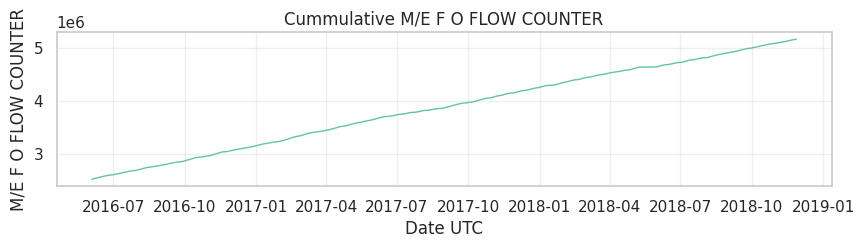

In [105]:
#Grafiquemos el contador acumulado

plt.figure(figsize=(10, 2))
plt.plot(df_train[COL_FECHA], df_train[COL_CONTADOR], lw=1)

plt.title('Cummulative M/E F O FLOW COUNTER')
plt.xlabel('Date UTC')
plt.ylabel('M/E F O FLOW COUNTER')
plt.grid(alpha=0.3)
plt.show()

Codifiquemos numericamente la intensidad del viento, para poder utilizarla en los modelos, dado que la variable catégorica inicial no será compatible con los modelos a implementar para el ajuste.

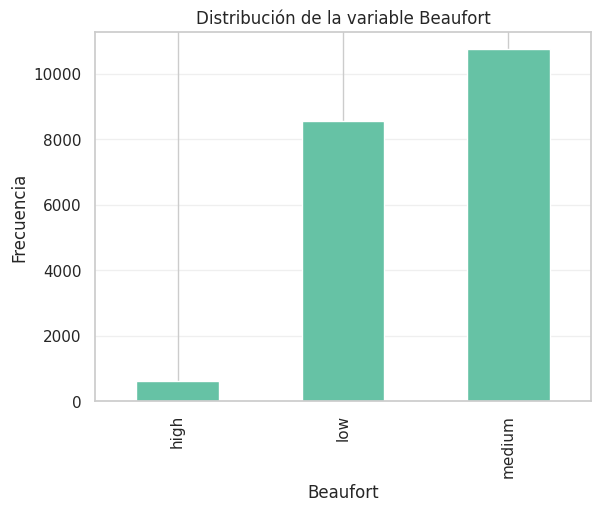

In [106]:
#Valores de Beaufort
df_train['Beaufort'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribución de la variable Beaufort')
plt.xlabel('Beaufort')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [107]:
# Codificación de la intensidad del viento
beaufort_map = {
    'low': 0,
    'medium': 1,
    'high': 2
}

df_train['Beaufort'] = df_train['Beaufort'].map(beaufort_map)
df_test['Beaufort'] = df_test['Beaufort'].map(beaufort_map)

display(df_train[['Beaufort']].head())
display(df_test[['Beaufort']].head())

,Beaufort
0,1
1,1
2,1
3,0
4,0


,Beaufort
0,0
1,0
2,0
3,0
4,0


#### 2.2. Integración el `DRAFT` (Profundidad o Calado)

<!-- #### 2.2. Incorporemos el calado profundidad (`DRAFT`)

El archivo `DataTrainVyg` contiene el calado y su fecha. Para asociarlo a las mediciones utilizamos la última observación de calado registrada hasta ese instante. -->

In [108]:
# Utilicemos el encabezado de DataTrainVyg para identificar las columnas de fecha y DRAFT (profundidad).
df_vyg.columns = df_vyg.columns.astype(str).str.strip()
fecha_vyg = next((c for c in df_vyg.columns if c.lower().replace(' ', '') in ['date(utc)', 'date', 'datetime(utc)']), None)
col_draft = next((c for c in df_vyg.columns if c.upper() == 'DRAFT'), None)

calados = df_vyg[[fecha_vyg, col_draft]].copy()
calados.columns = [COL_FECHA, 'DRAFT']
calados[COL_FECHA] = pd.to_datetime(calados[COL_FECHA], errors='coerce', utc=True).dt.tz_localize(None)
calados['DRAFT'] = pd.to_numeric(calados['DRAFT'], errors='coerce')
calados = calados.dropna(subset=[COL_FECHA, 'DRAFT']).sort_values(COL_FECHA)

# Si coinciden fechas exactas, se conserva el último registro de calado de esa fecha.
calados = calados.drop_duplicates(COL_FECHA, keep='last')

# Se conserva el orden original de DataTest para las predicciones finales.
df_test['_orden_test'] = np.arange(len(df_test))

def incorporar_calado(df):
    base = df.drop(columns=['DRAFT'], errors='ignore').sort_values(COL_FECHA)
    con_calado = pd.merge_asof(base, calados, on=COL_FECHA, direction='backward')
    return con_calado

df_train = incorporar_calado(df_train)
df_test = incorporar_calado(df_test)

display(df_train[[COL_FECHA, 'DRAFT']].head())

,Date,DRAFT
0,2016-06-03 03:00:00,9.35
1,2016-06-03 04:00:00,9.35
2,2016-06-03 05:00:00,9.35
3,2016-06-03 06:00:00,9.35
4,2016-06-03 07:00:00,9.35


Consideramos `Latitude_degree`, `Longitude_degree`, `Beaufort`, `Speed(Ground)`, `M/E REVOLUTION` y `DRAFT` como nuestro dataset de caracteristicas. Las fechas se utilizan para ordenar los datos, además el contador acumulado (*M/E F O FLOW COUNTER*) no estará dentro de las características.

Nótese que el calado `DRAFT` es un parámetro que permanece constante, dado que es una propiedad del navio.

,count,mean,std,min,25%,50%,75%,max
Latitude_degree,19931.0,33.014239,1.227938e+01,6.571944,25.297639,34.795000,41.515694,54.626944
Longitude_degree,19931.0,-29.937363,1.297151e+02,-180.195278,-130.346111,-80.981389,138.211806,180.217500
Beaufort,19931.0,0.601475,5.494839e-01,0.000000,0.000000,1.000000,1.000000,2.000000
Speed(Ground),19931.0,14.052195,5.895756e+00,0.000000,13.400000,16.500000,17.600000,22.100000
M/E REVOLUTION,19931.0,69.759520,2.912261e+01,0.000000,67.000000,83.000000,87.000000,95.000000
DRAFT,19931.0,9.350000,3.412467e-12,9.350000,9.350000,9.350000,9.350000,9.350000
Diferencia_combustible,19931.0,124.342783,6.302374e+01,0.000000,88.000000,148.000000,172.000000,211.000000


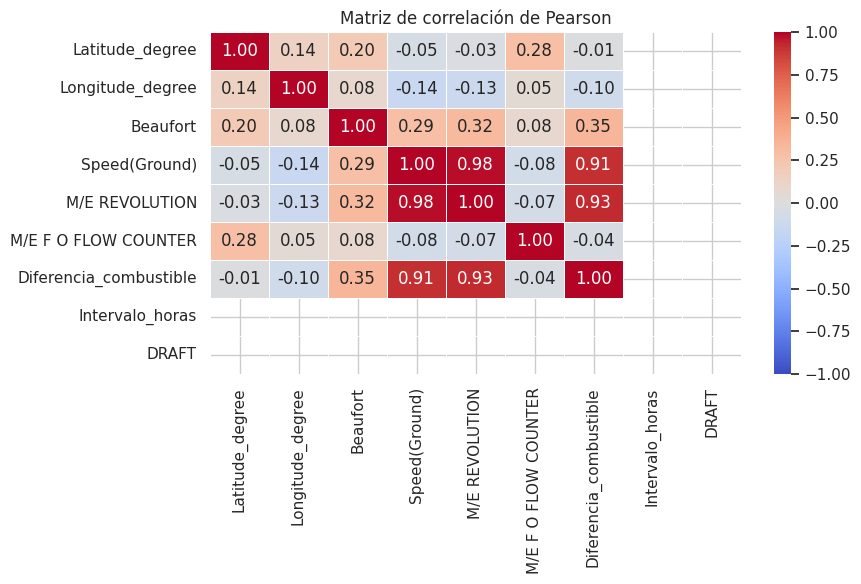

In [109]:
caracteristicas = [
    'Latitude_degree', 'Longitude_degree', 'Beaufort',
    'Speed(Ground)', 'M/E REVOLUTION', 'DRAFT'
]

for df in [df_train, df_test]:
    for c in caracteristicas:
        df[c] = pd.to_numeric(df[c], errors='coerce')

# Excluimos diferencias indefinidas ni negativas.
datos = df_train.dropna(subset=['Diferencia_combustible']).copy()
datos = datos[datos['Diferencia_combustible'] >= 0].reset_index(drop=True)

#Visualización del nuevo dataset de entrenamiento con las diferencias válidas
display(datos[caracteristicas + ['Diferencia_combustible']].describe().T)

# Obtengamos la correlación de Pearson entre las características y la variable objetivo  

# Seleccionamos únicamente las variables numéricas
datos_numericos = datos.select_dtypes(include='number')

# Calculamos la matriz de correlación de Pearson
corr = datos_numericos.corr()

# Visualizamos las correlaciones
plt.figure(figsize=(9, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title('Matriz de correlación de Pearson')
plt.tight_layout()
plt.show()

### 3. Entrenamiento y validación

Como los datos son registros sucesivos de un barco, mantenemos su orden cronológico, por lo que resulta apropiado realizar la división del dataset respetando esa condición de la siguiente manera: 80 % para entrenamiento (inicial)  y 20 % para validación (final).

In [110]:
#Calculemos temporalmente donde es el punto de corte para separar el conjunto de entrenamiento y validación (80% - 20%)
datos = datos.sort_values(COL_FECHA).reset_index(drop=True)
corte = int(len(datos) * 0.8)
#Hagamos el split de entrenamiento y validación
train = datos.iloc[:corte].copy()
valid = datos.iloc[corte:].copy()

X_train = train[caracteristicas].copy()
X_valid = valid[caracteristicas].copy()
y_train = train['Diferencia_combustible'].copy()
y_valid = valid['Diferencia_combustible'].copy()

print('Entrenamiento:', len(X_train), 'muestras')
print('Periodo de entrenamiento:', train[COL_FECHA].min(), 'a', train[COL_FECHA].max())
print("---------------------------------")
print('Validación:', len(X_valid), 'muestras')
print('Periodo de validación:', valid[COL_FECHA].min(), 'a', valid[COL_FECHA].max())
print("---------------------------------")
print("Proporcion final de entrenamiento y validación:", np.round(len(X_train) / len(datos), 2), "y", np.round(len(X_valid) / len(datos), 2))

print("Valores NaN en entrenamiento:")
display(X_train.isna().sum())

print("Valores NaN en validación:")
display(X_valid.isna().sum())

Entrenamiento: 15944 muestras
Periodo de entrenamiento: 2016-06-03 03:00:00 a 2018-06-10 22:00:00
---------------------------------
Validación: 3987 muestras
Periodo de validación: 2018-06-10 23:00:00 a 2018-11-27 09:00:00
---------------------------------
Proporcion final de entrenamiento y validación: 0.8 y 0.2
Valores NaN en entrenamiento:


,0
Latitude_degree,0
Longitude_degree,0
Beaufort,0
Speed(Ground),0
M/E REVOLUTION,0
DRAFT,0


Valores NaN en validación:


,0
Latitude_degree,0
Longitude_degree,0
Beaufort,0
Speed(Ground),0
M/E REVOLUTION,0
DRAFT,0


#### Utilizamos los siguientes modelos de entrenamiento:

- Regresión Lineal: `LinearRegression()`

- Árbol de Decisión: `DecisionTreeRegressor()`

- Random Forest: `RandomForestRegressor()`

Para las 3 implementaciones utilicemos como referencia las 3 métricas de error y correlación: MAE, RMSE, R<sup>2</sup>

In [111]:
#Declaremos los modelos a evaluar importados desde sklearn

modelos = {
    'Regresión lineal': LinearRegression(),

    #Arbol con profundidad máxima de 5 y mínimo de 5 muestras por hoja para evitar sobreajuste
    'Árbol de decisión': DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=SEED),

    #Random Forest con 100 estimadores, profundidad máxima de 8 y mínimo de 3 muestras por hoja para evitar sobreajuste
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=8,
                                          min_samples_leaf=3, random_state=SEED)
}


#Declaramos una función para evaluar los modelos y obtener métricas de desempeño MAE, RMSE y R²
def evaluar_modelo(y_real, y_estimado):
    return {
        'MAE': mean_absolute_error(y_real, y_estimado),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_estimado)),
        'R²': r2_score(y_real, y_estimado)
    }


resultados = []
predicciones_valid = {}

#Calculamos para referencia el valor promedio del consumo incremental de combustible
base = np.full(len(y_valid), y_train.mean(), dtype=float)
resultados.append({'Modelo': 'Promedio (referencia)', **evaluar_modelo(y_valid, base)})

#Evaluamos cada modelo anteriormente declarado
for nombre, modelo in modelos.items():

    #Se realiza el ajuste del modelo
    modelo.fit(X_train, y_train)

    #Se realiza la predicción en el conjunto de validación
    pred = modelo.predict(X_valid)

    #Se descartan las predicciones negativas (fisicamente no tiene sentido un consumo incremental negativo)
    pred = np.maximum(pred, 0)  # Consumo incremental no negativo

    predicciones_valid[nombre] = pred
    resultados.append({'Modelo': nombre, **evaluar_modelo(y_valid, pred)})


comparacion = pd.DataFrame(resultados).sort_values('MAE').reset_index(drop=True)
display(comparacion.round(4))

,Modelo,MAE,RMSE,R²
0,Random Forest,9.3193,14.9450,0.9386
1,Árbol de decisión,10.0839,16.0990,0.9288
2,Regresión lineal,13.4246,21.3608,0.8746
3,Promedio (referencia),48.1819,60.5235,-0.0069


#### 3.1. Comparación de modelos de regresión

Inicialmente, entrenamos los modelos sin considerar la regularidad de los intervalos entre mediciones. En esta primera evaluación, el árbol de decisión obtuvo el menor MAE (14.73 L), pero presentó un RMSE elevado de 107.86 L y un R² de -2.15. Por otra parte, la regresión lineal obtuvo el menor RMSE (27.34 L) y el mayor R² (0.80), mostrando un desempeño más consistente.

Al analizar los datos, identificamos que algunos registros estaban separados por intervalos de hasta 671 horas, lo que generaba diferencias de combustible considerablemente mayores que las habituales. Por esta razón, decidimos conservar únicamente mediciones consecutivas de una hora y entrenar nuevamente los modelos.

Después del filtrado, observamos una mejora general considerable en las métricas de los tres modelos. Random Forest obtuvo los mejores resultados, con un MAE de 9.32 L, un RMSE de 14.95 L y un R² de 0.94. Le sigue el árbol de decisión, con un MAE de 10.08 L y un R² de 0.93, mientras que la regresión lineal alcanzó un R² de 0.87.

Por tanto, seleccionamos Random Forest como el modelo con mejor desempeño en la validación de los registros horarios, para realizar las predicciones sobre `DataTest`.

#### 3.2. Veamos como se comportan las predicciones en cada uno de los 3 modelos

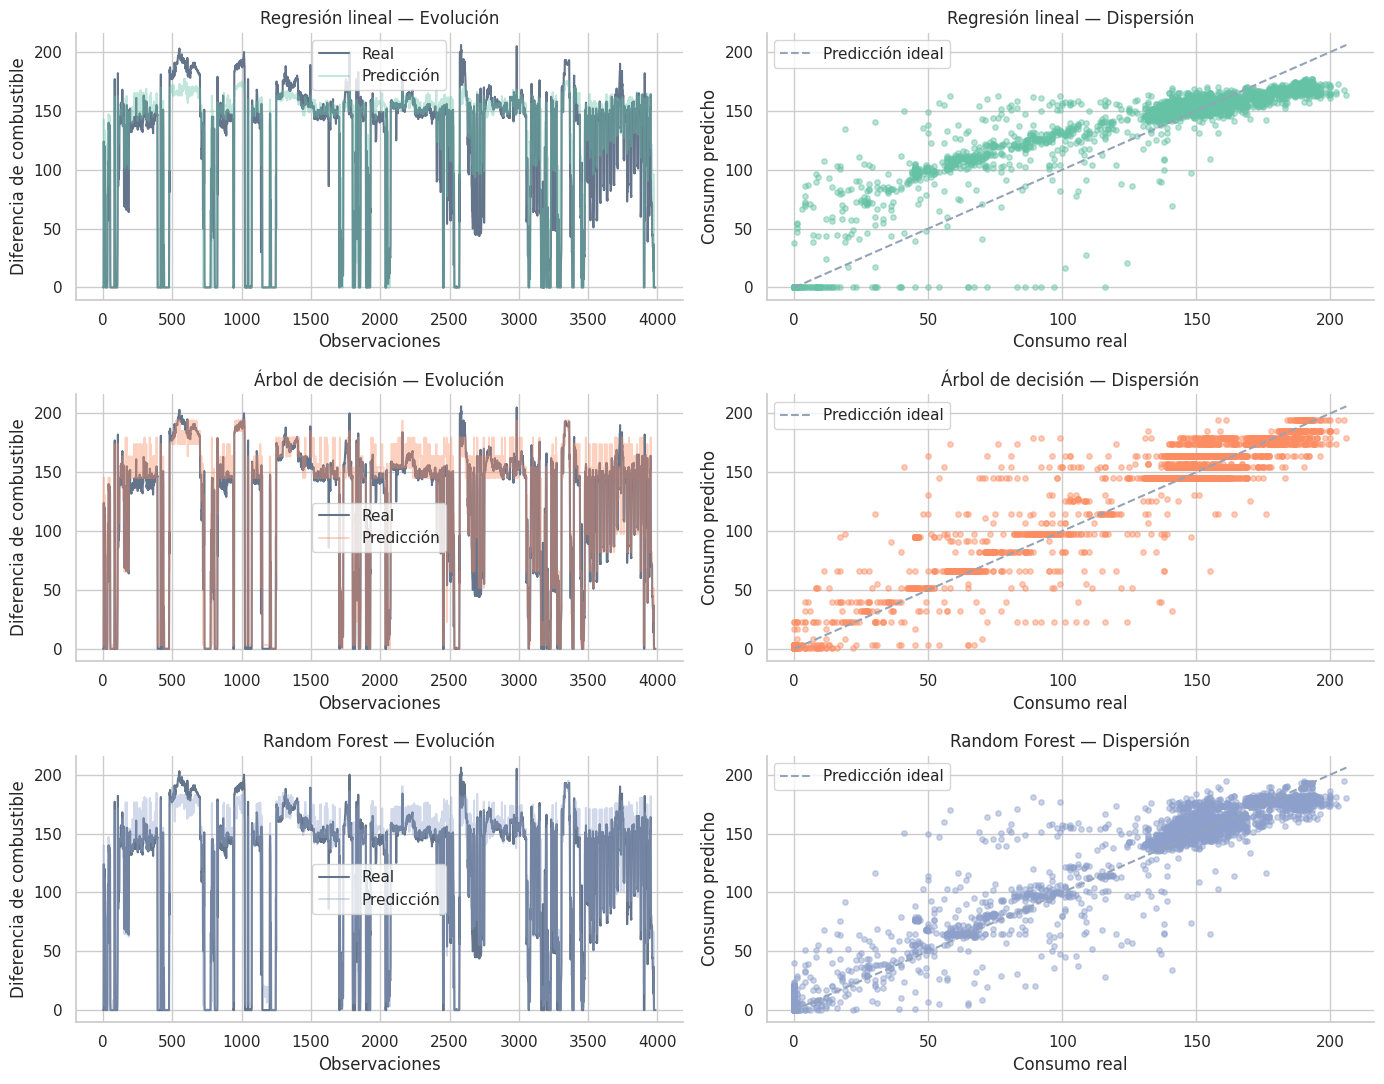

In [113]:
sns.set_theme(style="whitegrid", palette="Set2")

colores = sns.color_palette("Set2", 3)
y_real = np.asarray(y_valid)

fig, ax = plt.subplots(3, 2, figsize=(14, 11))

for i, (nombre, pred) in enumerate(predicciones_valid.items()):

    # Gráfica 1: evolución de valores reales y predichos
    ax[i, 0].plot(
        y_real, color="#64748b",
        linewidth=1.5, label="Real"
    )
    ax[i, 0].plot(
        pred, color=colores[i],
        linewidth=1.4, alpha=0.40, label="Predicción"
    )

    ax[i, 0].set_title(f"{nombre} — Evolución")
    ax[i, 0].set_xlabel("Observaciones")
    ax[i, 0].set_ylabel("Diferencia de combustible")
    ax[i, 0].legend()

    # Gráfica 2: dispersión real vs predicho
    ax[i, 1].scatter(
        y_real, pred,
        color=colores[i],
        alpha=0.45, s=15
    )

    # Línea de predicción ideal
    limite = max(y_real.max(), np.max(pred))
    ax[i, 1].plot(
        [0, limite], [0, limite],
        linestyle="--", color="#94a3b8",
        linewidth=1.5, label="Predicción ideal"
    )

    ax[i, 1].set_title(f"{nombre} — Dispersión")
    ax[i, 1].set_xlabel("Consumo real")
    ax[i, 1].set_ylabel("Consumo predicho")
    ax[i, 1].legend()

sns.despine()
plt.tight_layout()
plt.show()

### Realizemos un entrenamiento final y la predicción de `DataTest`

Una vez comparados los modelos, reentrenamos el mejor con `DataTrain`. Generamos la diferencia de combustible predicha para cada fila de `DataTest`.

,Date,Diferencia_combustible_predicha
0,2018-11-27 10:00:00,0.278556
1,2018-11-27 11:00:00,0.243605
2,2018-11-27 12:00:00,0.241979
3,2018-11-27 13:00:00,0.241979
4,2018-11-27 14:00:00,0.241979
5,2018-11-27 15:00:00,0.251012
6,2018-11-27 16:00:00,0.278556
7,2018-11-27 17:00:00,0.251012
8,2018-11-27 18:00:00,0.241979
9,2018-11-27 19:00:00,0.243605


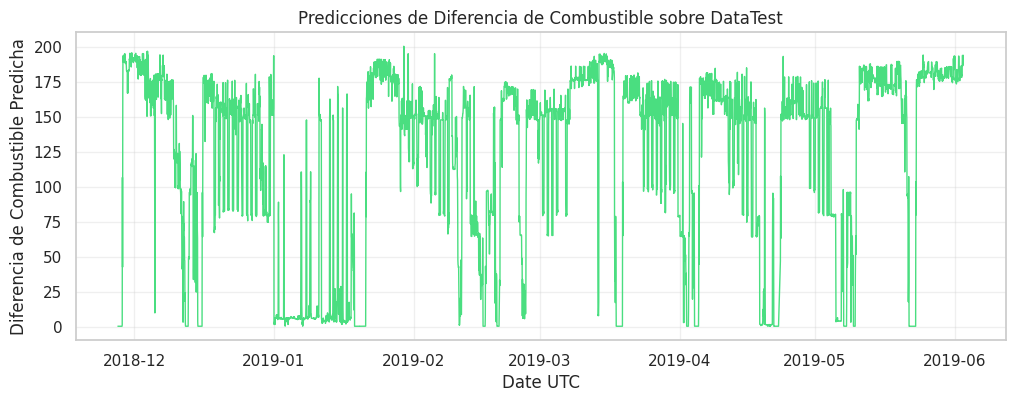

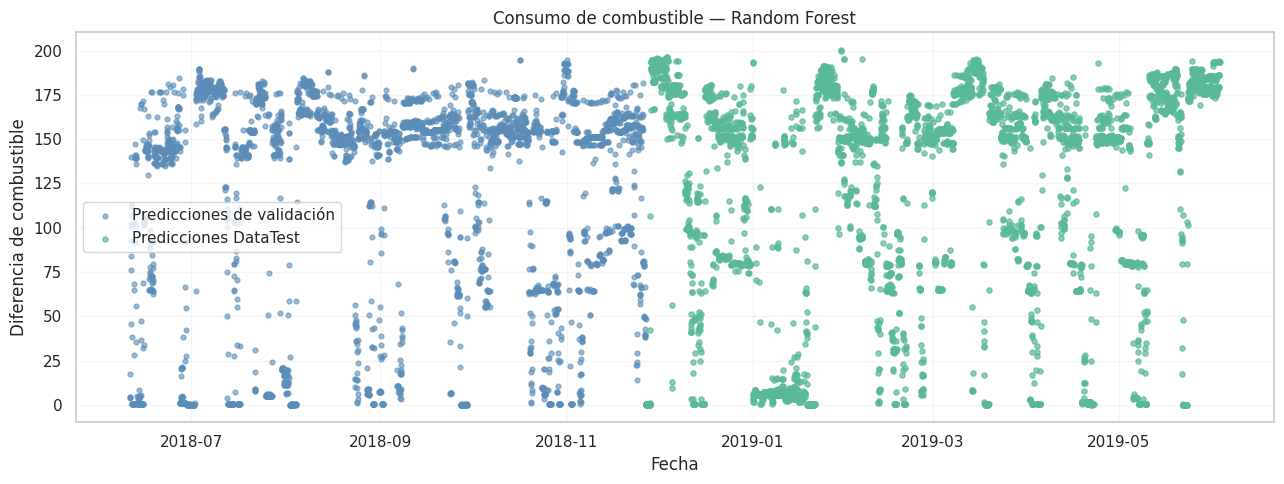

In [114]:
# Selección manual del modelo después de comparar los resultados
# Opciones: 'Regresión lineal', 'Árbol de decisión', 'Random Forest'

modelo_elegido = 'Random Forest'

modelo_final = modelos[modelo_elegido]

# Entrenamiento final con todos los datos disponibles
X_total = datos[caracteristicas].copy()
X_total = X_total.fillna(X_total)

y_total = datos['Diferencia_combustible']

modelo_final.fit(X_total, y_total)

# Predicción sobre el conjunto DataTest
X_test = df_test[caracteristicas]
pred_test = np.maximum(modelo_final.predict(X_test), 0)

# Recuperamos el orden original de DataTest
salida = df_test[['_orden_test', COL_FECHA]].copy()
salida['Diferencia_combustible_predicha'] = pred_test

# Ordenamos la salida por el orden original de DataTest y eliminamos la columna auxiliar '_orden_test'
salida = (
    salida.sort_values('_orden_test')
    .drop(columns='_orden_test')
    .reset_index(drop=True)
)

display(salida.head(10))

# Visualización de las predicciones finales y comparación con los valores reales
plt.figure(figsize=(12, 4))
plt.plot(salida[COL_FECHA], salida['Diferencia_combustible_predicha'], lw=1, color="#4ade80")
plt.title('Predicciones de Diferencia de Combustible sobre DataTest')
plt.xlabel('Date UTC')
plt.ylabel('Diferencia de Combustible Predicha')
plt.grid(alpha=0.3)
plt.show()


#GRAFIQUEMOS A CONTINUACIÓN LAS PREDICCIONES DEL MODELO ELEGIDO EN VALIDACIÓN Y DATA TEST

# Predicciones del modelo seleccionado en validación
pred_valid = predicciones_valid[modelo_elegido]

fig, ax = plt.subplots(figsize=(13, 5))

# Predicciones del conjunto de validación
ax.scatter(
    datos.loc[X_valid.index, COL_FECHA],
    pred_valid,
    s=12, alpha=0.6,
    color="#5b8db8",
    label="Predicciones de validación"
)

# Predicciones sobre DataTest
ax.scatter(
    salida[COL_FECHA],
    salida['Diferencia_combustible_predicha'],
    s=14, alpha=0.7,
    color="#59b89a",
    label="Predicciones DataTest"
)

ax.set_title(f"Consumo de combustible — {modelo_elegido}")
ax.set_xlabel("Fecha")
ax.set_ylabel("Diferencia de combustible")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

La matriz de correlación de Pearson muestra una fuerte asociación entre la diferencia de combustible y las variables Speed(Ground) (r = 0.91) y M/E REVOLUTION (r = 0.93).

Por esta razón, comparamos las predicciones del Random Forest sobre DataTest con estas variables de navegación, cuyos valores sí conocemos.

Esta comparación permite evaluar si las predicciones mantienen un comportamiento consistente con las relaciones observadas durante el entrenamiento. Sin embargo, al no disponer del consumo real de DataTest, no es posible cuantificar directamente el error de estas predicciones.

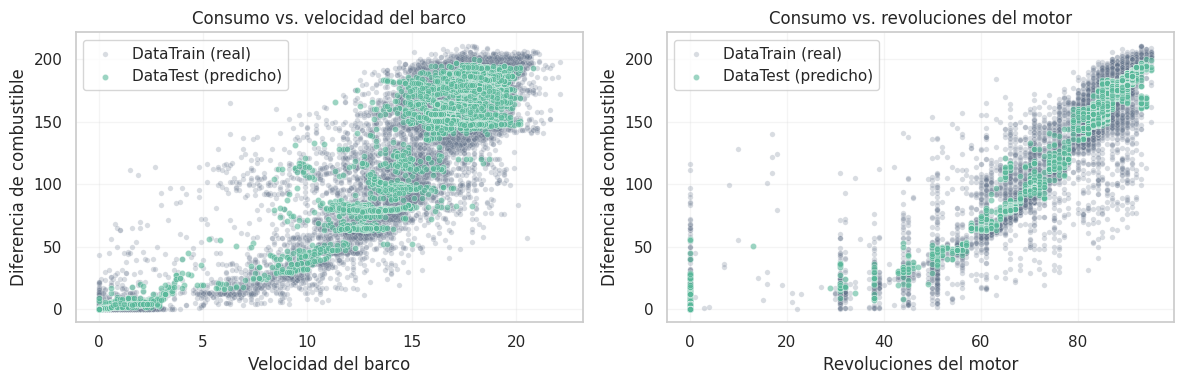

In [119]:
# Comparación entre los datos reales de DataTrain y las predicciones de DataTest

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

variables = ['Speed(Ground)', 'M/E REVOLUTION']
titulos = ['Velocidad del barco', 'Revoluciones del motor']

for i, variable in enumerate(variables):

    # Datos reales de entrenamiento
    sns.scatterplot(
        x=datos[variable],
        y=datos['Diferencia_combustible'],
        color='#64748b',
        alpha=0.25,
        s=15,
        label='DataTrain (real)',
        ax=ax[i]
    )

    # Predicciones sobre DataTest
    sns.scatterplot(
        x=df_test[variable],
        y=pred_test,
        color='#59b89a',
        alpha=0.6,
        s=20,
        label='DataTest (predicho)',
        ax=ax[i]
    )

    ax[i].set_xlabel(titulos[i])
    ax[i].set_ylabel('Diferencia de combustible')
    ax[i].set_title(f'Consumo vs. {titulos[i].lower()}')
    ax[i].legend()
    ax[i].grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Conclusión

Se entrenan y comparan tres modelos de regresión para estimar la diferencia del contador de combustible de un barco a partir de sus condiciones de navegación.

El análisis exploratorio permitió identificar que los intervalos irregulares entre mediciones afectaban significativamente los resultados. Después de conservar únicamente registros horarios consecutivos, obtuvimos mejores métricas de validación.

El modelo Random Forest presentó el mejor desempeño, con un MAE de 9.32, RMSE de 14.95 y R² de 0.94. Además, encontramos una fuerte correlación entre el consumo de combustible, la velocidad del barco y las revoluciones del motor.

Finalmente, utilizamos el modelo seleccionado para generar predicciones sobre `DataTest`. Aunque no disponemos de los valores reales de consumo para evaluar estas predicciones, su comparación con los datos históricos permite examinar si mantienen un comportamiento consistente con las condiciones de operación.